In [1]:
import logging
logging.basicConfig(level=logging.INFO, force=True)


from networkx.drawing import (
    draw as nx_draw,
    spring_layout,
    kamada_kawai_layout ,
)

from mupt.trees.subselect import NodePredicate
from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
    CompositePrimitive,
)
from mupt.mupr.properties import is_atom, is_superatomic, is_subdominant

from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

INFO:rdkit:Enabling RDKit 2026.09.1 jupyter extensions
INFO:freud.msd:Using SciPy's fftpack for FFTs


# Linear PAAm homopolymer

In [2]:
num_mols : int = 3
DOP : int = 10

## Assemble MuPT repr

In [3]:
lexicon = {
    'head' : primitive_from_smiles('[H:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]', label="_A"),
    'mid'  : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[*:2]', label="_B"),
    'tail' : primitive_from_smiles('[*:1]-[C:2]CC(=O)[N:1](-[H])-[H:2]', label="_C"),
}

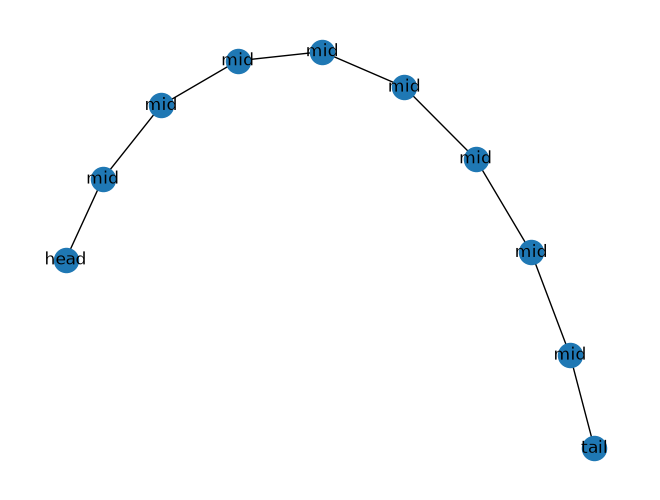

In [4]:
from networkx import get_node_attributes, connected_components
from mupt.graphs.generators import path_graph_from_sequence


label_attr : str = 'label'
sequence_graph = path_graph_from_sequence(
    ['head'] + (DOP - 2)*['mid'] + ['tail'],
    label_attr=label_attr,
)

nx_draw(
    sequence_graph,
    with_labels=True,
    labels=get_node_attributes(sequence_graph, label_attr),
)

### Select, connect, then inspect

In [5]:
# predicate : NodePredicate[Primitive] = lambda prim : is_atom(prim) and prim.element.symbol != 'H'
# predicate : NodePredicate[Primitive] = lambda prim: isinstance(prim.parent, CompositePrimitive)
# predicate : NodePredicate[Primitive] = is_superatomic
predicate : NodePredicate[Primitive] = is_superatomic

In [6]:
molprim_prototype = CompositePrimitive()
molprim_prototype.populate_from_topology_and_lexicon(
    sequence_graph,
    lexicon,
    label_attr=label_attr,
)

system = RootPrimitive(label='system')
for i in range(num_mols):
    molprim = molprim_prototype.copy()
    molprim.label = f'molecule_{i}'
    system.attach_child(molprim)

INFO:mupt.mupr.connection.linking:Paired up 9 new edges after 1 iteration(s); 0/9 edges remain unpaired
INFO:mupt.mupr.connection.linking:Linking protocol successful! 9/9 edges were assigned Connector pairings


In [7]:
xsec = system.cross_section(predicate)
print(f'{len(list(connected_components(xsec)))} molecules')

3 molecules


<Axes: >

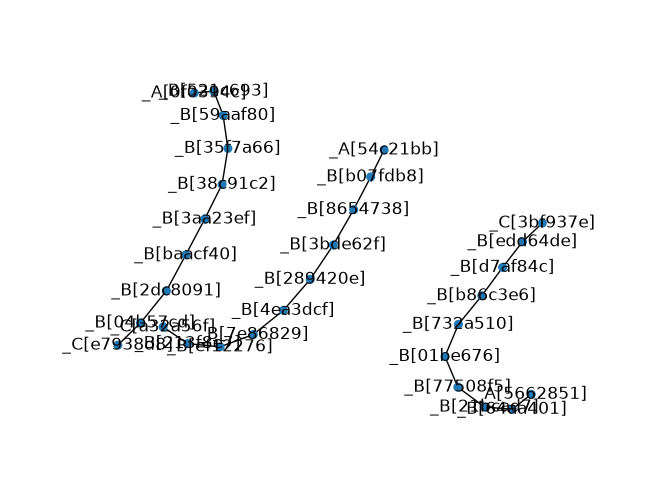

In [8]:
pos = spring_layout(xsec, dim=2)
system.visualize_cross_section(xsec, pos=pos, with_labels=True, node_size=30)

## Export to mbuild

In [9]:
compound = primitive_to_mbuild(
    system,
    predicate=predicate,
    # set False (default) to have Particles directly on Compound
    preserve_intermediates=True, 
)
... # insert downstream code here
print(compound)

<system 30 particles, 27 bonds, non-periodic, id: 5891176976>


In [10]:
# inspect direct descendants of "root" Compound which is returned
display(set(subcomp.name for subcomp in compound.children))

{'molecule_0', 'molecule_1', 'molecule_2'}

from mupt.chemistry.rdkit.depiction import set_rdkdraw_size, hide_atom_indices

set_rdkdraw_size(500, 3/2)
hide_atom_indices()

mols = compound.to_rdkit()
for atom in mols.GetAtoms():
    atom.ClearProp('atomLabel')
display(mols)

# PAMAM dendrimer

In [11]:
print(molprim.hierarchy_summary())

molecule_2
├── _A
│   ├── H-0
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
├── _B
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── O-4
│   ├── N-5
│   ├── H-6
│   ├── H-8
│   ╰── H-9
╰── _C
    ├── C-1
    ├── C-2
    ├── C-3
    ├──

### Pass mbuild compound to FlowerMD. 
- Set coordinates with a non-self-avoiding random walk.
- Relax positions with a HOOMD simulation of DPD and FIRE (PhantomWalk).

In [12]:
from flowermd.library import RandomWalk
import unyt as u

from flowermd.library import Bead_Spring_DPD #check which xml your environment is pointing at
import hoomd

from flowermd.library import PhantomWalk

import warnings
import copy
warnings.filterwarnings("ignore")
from flowermd.base import Molecule

molecules = Molecule(
    num_mols=1, compound=compound, name="PAAm", identify_connections=False
)

ref_length = 1.0 * u.Unit("nm")
ref_mass = 1.0 * u.Unit("g/mol")
ref_energy = 1.0 * u.Unit("kcal / mol")
ref_values_dict = {"length": ref_length, "mass": ref_mass, "energy": ref_energy}

system = RandomWalk(
    molecules=molecules,
    density=0.8 * u.Unit("nm**-3"),
    bond_length=0.2,
    base_units=ref_values_dict,
    seed=456,
)

nlist = hoomd.md.nlist.Cell(buffer=0.1, exclusions=["bond"])
system.apply_forcefield(
    force_field=Bead_Spring_DPD(), kT=1.0, r_cut=1.01, nlist=nlist
)

sim = PhantomWalk(
    initial_state=system.hoomd_snapshot,
    forcefield=system.hoomd_forcefield,
    gsd_write_freq=100,
    log_write_freq=50,
    n_steps_dpd=500,
    n_steps_fire=100,
    write_at_start=True,
)

for writer in sim.operations.writers:
    if isinstance(writer, hoomd.write.GSD):
        writer.flush()

INFO:numexpr.utils:NumExpr defaulting to 11 threads.


Initializing simulation state from a gsd.hoomd.Frame.
Step 75 of 500; TPS: 645.79; ETA: 0.0 minutes
Step 150 of 500; TPS: 1280.14; ETA: 0.0 minutes
Step 225 of 500; TPS: 1905.54; ETA: 0.0 minutes
Step 300 of 500; TPS: 2521.47; ETA: 0.0 minutes
Step 375 of 500; TPS: 3130.37; ETA: 0.0 minutes
Step 450 of 500; TPS: 3730.2; ETA: 0.0 minutes
Step 25 of 100; TPS: 373134.33; ETA: 0.0 minutes
The closest particles after DPD + FIRE are:  1.002750039100647


### Set positions from simulation to your GMSO system.

In [13]:
snap = sim.state.get_snapshot()
system.update_positions(snapshot=snap)

### Export through GMSO.

In [14]:
#remove hoomd dpd forcefield typing
system.remove_typing()

In [15]:
#apply a lammps-compatible forcefield
from flowermd.base import BaseXMLForcefield
xml_path_pair_expressions = "../utilities/gmso_xmls/cg-lammps-pair.xml"
lammps_ff_p = BaseXMLForcefield(forcefield_files=xml_path_pair_expressions,gmso_xml=True)

In [16]:
from gmso.parameterization import apply
apply(top=system.gmso_system, forcefields=lammps_ff_p.gmso_ff, identify_connections=False)

<Topology Topology, 30 sites,
 27 connections,
 63 potentials,
 id: 5966197328>

In [17]:
from gmso.formats.lammpsdata import write_lammpsdata
write_lammpsdata(system.gmso_system, filename="cg-PAAm.lammps", atom_style="full")